In [ ]:
import os
import numpy as np
import pandas as pd

from google.colab import drive
drive.mount("/content/drive")

PASTA = "/content/drive/MyDrive/projeto-classificacao"
CAMINHO_CACHE = f"{PASTA}/told_br.parquet"
os.makedirs(PASTA, exist_ok=True)

URL = "https://raw.githubusercontent.com/JAugusto97/ToLD-Br/main/ToLD-BR.csv"

TEM_CACHE = os.path.exists(CAMINHO_CACHE)
print("Cache encontrado:", TEM_CACHE, "|", CAMINHO_CACHE)

if not TEM_CACHE:
    print("Baixando do GitHub...")
    df = pd.read_csv(URL)
    df.to_parquet(CAMINHO_CACHE, index=False)
    print("Baixado e salvo no Drive.")
else:
    print("Lendo do arquivo local.")
    df = pd.read_parquet(CAMINHO_CACHE)

print(df.shape)
df.head()

Mounted at /content/drive
Cache encontrado: False | /content/drive/MyDrive/projeto-classificacao/told_br.parquet
Baixando do GitHub...
Baixado e salvo no Drive.
(21000, 7)


,text,homophobia,obscene,insult,racism,misogyny,xenophobia
0,Meu nivel de amizade com isis é ela ter meu in...,0.0,0.0,2.0,0.0,0.0,0.0
1,"rt @user @user o cara adultera dados, que fora...",0.0,0.0,1.0,0.0,0.0,0.0
2,@user @user @user o cara só é simplesmente o m...,0.0,2.0,1.0,0.0,0.0,0.0
3,eu to chorando vei vsf e eu nem staneio izone ...,0.0,1.0,0.0,0.0,0.0,0.0
4,Eleitor do Bolsonaro é tão ignorante q não per...,0.0,1.0,2.0,0.0,0.0,0.0


# Criação da coluna única de classe (rótulo multiclasse)


O ToLD-Br é multirrótulo (6 colunas com votos de 0 a 3 anotadores); aqui viro isso em uma única
classe por tweet: a categoria mais votada se ao menos 2 anotadores concordaram, senão "nenhuma".

In [ ]:
cols = ["homophobia", "obscene", "insult", "racism", "misogyny", "xenophobia"]

maior = df[cols].max(axis=1)
df["classe"] = np.where(maior >= 2, df[cols].idxmax(axis=1), "nenhuma")

print(df["classe"].value_counts())

classe
nenhuma       16937
obscene        2296
insult         1502
homophobia      169
misogyny         44
xenophobia       31
racism           21
Name: count, dtype: int64


# Estudo Introdutório

In [ ]:
# ## Estudo introdutório: visão geral da base
# Mostra tamanho, colunas, tipos, nulos, duplicados e distribuição (absoluta e %) das classes.

print("Formato:", df.shape)
print("\nColunas:", list(df.columns))
print("\nNulos por coluna:\n", df.isnull().sum())
print("\nTextos duplicados:", df["text"].duplicated().sum())

dist = df["classe"].value_counts()
print("\nDistribuição das classes:")
print(pd.DataFrame({"qtd": dist, "%": (dist / len(df) * 100).round(2)}))

Formato: (21000, 8)

Colunas: ['text', 'homophobia', 'obscene', 'insult', 'racism', 'misogyny', 'xenophobia', 'classe']

Nulos por coluna:
 text          0
homophobia    0
obscene       0
insult        0
racism        0
misogyny      0
xenophobia    0
classe        0
dtype: int64

Textos duplicados: 187

Distribuição das classes:
              qtd      %
classe                  
nenhuma     16937  80.65
obscene      2296  10.93
insult       1502   7.15
homophobia    169   0.80
misogyny       44   0.21
xenophobia     31   0.15
racism         21   0.10


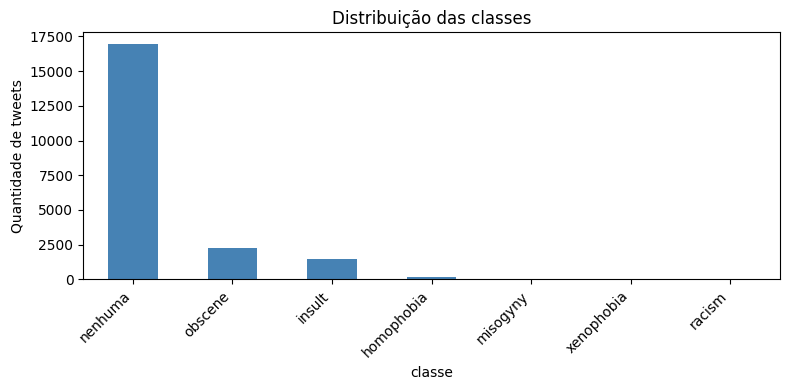

In [ ]:
# ## Estudo introdutório: gráfico de distribuição das classes
# Barras com a quantidade de tweets por classe, para visualizar o desbalanceamento.

import matplotlib.pyplot as plt

dist.plot(kind="bar", figsize=(8, 4), color="steelblue")
plt.title("Distribuição das classes")
plt.ylabel("Quantidade de tweets")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [ ]:
# ## Estudo introdutório: tamanho dos textos
# Calcula nº de palavras por tweet e mostra estatísticas gerais e a média por classe.

df["n_palavras"] = df["text"].str.split().str.len()

print(df["n_palavras"].describe())
print("\nMédia de palavras por classe:")
print(df.groupby("classe")["n_palavras"].mean().round(1))

count    21000.000000
mean        15.628905
std         11.655742
min          1.000000
25%          7.000000
50%         12.000000
75%         20.000000
max         67.000000
Name: n_palavras, dtype: float64

Média de palavras por classe:
classe
homophobia    14.2
insult        16.6
misogyny      13.4
nenhuma       15.6
obscene       15.2
racism        14.7
xenophobia    16.1
Name: n_palavras, dtype: float64


In [ ]:
# ## Estudo introdutório: exemplos por classe
# Imprime 2 tweets aleatórios de cada classe para entender qualitativamente o conteúdo.

for c in df["classe"].unique():
    print(f"\n=== {c} ===")
    for t in df[df["classe"] == c]["text"].sample(2, random_state=42):
        print("-", t[:200])


=== insult ===
- vai se fuder que time ruim cadê o freire e o hawk seus zé ruela
- jr some, mermão pqp

=== nenhuma ===
- @user mal posso esperar pra taebaekai dar dinheiro pra esse unit e as fãs da sm inda falarem mal
- @user corre que a federal t谩 chegando

=== obscene ===
- meu melhor amigo tá namorando vai se fuder aaaaaa😍😍
- @user para o redpass dá o cu ao vieira.

=== xenophobia ===
- @user carioca é dramático demais.....😂😂😂😂😂 https://t.co/onxd1dalu6
- rt @user @user @user hahahahahahahahahah completamente bitolado. bolha f茅tida paulista. vcs nunca v茫o manipular a hist贸ria!

=== racism ===
- Segue minha página de shitpost @user
Mas é de humor negro/shitpost então se tu não gosta sai

Eu divido essa página com a minha melhor amiga segue ela tbm @user :&gt;
- satisfação da porra quando o django mete o cassete nos brancos.

=== homophobia ===
- @user @user agr pergunta quantos são sócios/vao aos jogos 
torcida viadinha tnc
- rt @user sonho de toda bichinha otaria  https://t.co/egm5

# Remoção de Textos Duplicados

In [ ]:
# ## Remoção de textos duplicados
# Remove tweets com texto repetido (mantém o primeiro) para evitar o mesmo texto cair em treino e teste.

antes = len(df)
df = df.drop_duplicates(subset="text", keep="first").reset_index(drop=True)
print(f"Removidos: {antes - len(df)} | Restantes: {len(df)}")

Removidos: 187 | Restantes: 20813


In [ ]:
# ## Agrupamento das classes minoritárias
# Junta racism, xenophobia e misogyny em "odio_identitario", pois sozinhas têm poucos exemplos para split e métricas confiáveis.

df["classe"] = df["classe"].replace({
    "racism": "odio_identitario",
    "xenophobia": "odio_identitario",
    "misogyny": "odio_identitario",
})

dist = df["classe"].value_counts()
print(pd.DataFrame({"qtd": dist, "%": (dist / len(df) * 100).round(2)}))

                    qtd      %
classe                        
nenhuma           16783  80.64
obscene            2276  10.94
insult             1489   7.15
homophobia          169   0.81
odio_identitario     96   0.46


Rodar Novamente o Gráfico de Distribuição

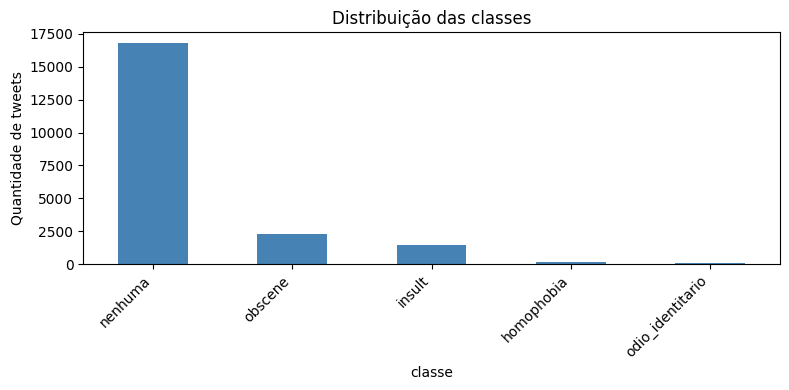

In [ ]:
# ## Estudo introdutório: gráfico de distribuição das classes
# Barras com a quantidade de tweets por classe, para visualizar o desbalanceamento.

import matplotlib.pyplot as plt

dist.plot(kind="bar", figsize=(8, 4), color="steelblue")
plt.title("Distribuição das classes")
plt.ylabel("Quantidade de tweets")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# Split 60/20/20

In [ ]:
# ## Split estratificado 60/20/20
# Divide em treino (60%), validação (20%) e teste (20%) mantendo a proporção das classes em cada parte.

from sklearn.model_selection import train_test_split

SEED = 42

X = df["text"]
y = df["classe"]

# 1) separa 20% para teste
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED
)

# 2) do restante (80%), separa 25% para validação (= 20% do total)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.25, stratify=y_temp, random_state=SEED
)

print(f"Treino: {len(X_train)} | Validação: {len(X_val)} | Teste: {len(X_test)}")

Treino: 12487 | Validação: 4163 | Teste: 4163


In [ ]:
# ## Conferência do split
# Mostra a quantidade de tweets por classe em treino, validação e teste para checar a estratificação.

conf = pd.DataFrame({
    "treino": y_train.value_counts(),
    "validacao": y_val.value_counts(),
    "teste": y_test.value_counts(),
})
print(conf)

                  treino  validacao  teste
classe                                    
nenhuma            10069       3357   3357
obscene             1366        455    455
insult               893        298    298
homophobia           101         34     34
odio_identitario      58         19     19


# TF-IDF sobre os textos

In [ ]:
# ## TF-IDF sobre os textos
# Transforma os tweets em vetores numéricos; o vocabulário é aprendido só no treino para não vazar informação.

from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(max_features=5000, ngram_range=(1, 2), min_df=2, lowercase=True)

X_train_tfidf = tfidf.fit_transform(X_train)
X_val_tfidf = tfidf.transform(X_val)
X_test_tfidf = tfidf.transform(X_test)

print("Formato treino:", X_train_tfidf.shape)
print("Formato validação:", X_val_tfidf.shape)
print("Formato teste:", X_test_tfidf.shape)

Formato treino: (12487, 5000)
Formato validação: (4163, 5000)
Formato teste: (4163, 5000)


In [ ]:
# ## Inspeção do vocabulário TF-IDF
# Mostra o tamanho do vocabulário e uma amostra de termos, para conferir se o TF-IDF capturou palavras relevantes.

termos = tfidf.get_feature_names_out()
print("Tamanho do vocabulário:", len(termos))
print("Amostra de termos:", list(termos[:20]))

Tamanho do vocabulário: 5000
Amostra de termos: ['00', '02', '02 08', '03', '03 08', '04', '06', '07', '08', '08 2019', '10', '10 anos', '100', '11', '12', '13', '14', '15', '16', '17']


In [ ]:
# ## Termos mais relevantes do TF-IDF
# Lista os 20 termos com maior peso médio no treino e uma amostra do meio do vocabulário, para ver o que o TF-IDF realmente captura.

pesos = np.asarray(X_train_tfidf.mean(axis=0)).ravel()
top = np.argsort(pesos)[::-1][:20]
print("Top 20 termos por peso médio:", [termos[i] for i in top])
print("\nAmostra do meio do vocabulário:", list(termos[2500:2520]))

Top 20 termos por peso médio: ['user', 'que', 'de', 'eu', 'user user', 'https', 'https co', 'co', 'rt', 'rt user', 'do', 'não', 'pqp', 'pra', 'da', 'no', 'porra', 'um', 'caralho', 'com']

Amostra do meio do vocabulário: ['mermo', 'mermão', 'mesa', 'meses', 'mesma', 'mesma coisa', 'mesmo', 'mesmo assim', 'mesmo não', 'mesmo pq', 'mesmo que', 'mesmo tempo', 'mesmos', 'messi', 'mestre', 'meta', 'metade', 'metade do', 'mete', 'metendo']


In [ ]:
# ## TF-IDF com limpeza (opcional)
# Refaz o TF-IDF removendo termos numéricos e muito frequentes (max_df), mantendo só palavras de pelo menos 2 letras.

tfidf = TfidfVectorizer(
    max_features=5000, ngram_range=(1, 2), min_df=2, max_df=0.5,
    lowercase=True, token_pattern=r"(?u)\b[^\W\d_]{2,}\b"
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_val_tfidf = tfidf.transform(X_val)
X_test_tfidf = tfidf.transform(X_test)

termos = tfidf.get_feature_names_out()
print("Formato treino:", X_train_tfidf.shape)
print("Amostra de termos:", list(termos[:20]))

Formato treino: (12487, 5000)
Amostra de termos: ['aaa', 'aaaa', 'aaaaaa', 'abel', 'aberração', 'abraço', 'abre', 'abri', 'abrir', 'abriu', 'absolutamente', 'absurdo', 'absurdos', 'acaba', 'acabando', 'acabar', 'acabar com', 'acabei', 'acabei de', 'acabo']


# Logistic Regression com Gradient Descent sem regularização

In [ ]:
# ## Treino da LR com Gradient Descent (sem regularização)
# Treina a regressão logística via SGD sem penalidade, com class_weight balanceado por causa das classes minoritárias.

from sklearn.linear_model import SGDClassifier

lr_gd = SGDClassifier(
    loss="log_loss", penalty=None, class_weight="balanced",
    max_iter=1000, tol=1e-3, random_state=42
)
lr_gd.fit(X_train_tfidf, y_train)
print("Iterações até convergir:", lr_gd.n_iter_)

Iterações até convergir: 61


In [ ]:
# ## Predição na validação
# Gera as classes previstas para o conjunto de validação (o teste fica reservado para a avaliação final).

pred_val_lr = lr_gd.predict(X_val_tfidf)
pred_val_lr

array(['nenhuma', 'nenhuma', 'nenhuma', ..., 'nenhuma', 'nenhuma',
       'nenhuma'], dtype='<U16')

In [ ]:
# ## Métricas na validação: precision, recall, micro F1 e macro F1
# Avalia o modelo na validação; o macro F1 trata todas as classes igualmente, o que importa com classes pequenas.

from sklearn.metrics import f1_score, classification_report

print("F1 micro:", f1_score(y_val, pred_val_lr, average="micro"))
print("F1 macro:", f1_score(y_val, pred_val_lr, average="macro"))
print()
print(classification_report(y_val, pred_val_lr, zero_division=0))

F1 micro: 0.7701177035791497
F1 macro: 0.4117140427561621

                  precision    recall  f1-score   support

      homophobia       0.23      0.47      0.30        34
          insult       0.40      0.42      0.41       298
         nenhuma       0.88      0.86      0.87      3357
         obscene       0.39      0.37      0.38       455
odio_identitario       0.06      0.21      0.09        19

        accuracy                           0.77      4163
       macro avg       0.39      0.47      0.41      4163
    weighted avg       0.78      0.77      0.78      4163



oq mostra ali encima:
F1 micro: 0,77, que é igual à acurácia e é puxado pela classe nenhuma (80% dos dados).
F1 macro: 0,41, o número mais honesto, e mostra que o modelo vai mal nas classes minoritárias.

# LR-GD com Ridge, Lasso e Elastic Net

In [ ]:
# ## LR-GD com Ridge, Lasso e Elastic Net
# Treina três variações da LR-GD trocando só a regularização (L2, L1 e L1+L2) e compara com o modelo sem regularização na validação.

from sklearn.linear_model import SGDClassifier
from sklearn.metrics import f1_score

configs = {
    "sem_reg":     dict(penalty=None),
    "ridge":       dict(penalty="l2", alpha=1e-4),
    "lasso":       dict(penalty="l1", alpha=1e-4),
    "elastic_net": dict(penalty="elasticnet", alpha=1e-4, l1_ratio=0.5),
}

modelos_lr = {}
for nome, cfg in configs.items():
    m = SGDClassifier(
        loss="log_loss", class_weight="balanced",
        max_iter=1000, tol=1e-3, random_state=42, **cfg
    )
    m.fit(X_train_tfidf, y_train)
    modelos_lr[nome] = m
    pred = m.predict(X_val_tfidf)
    print(f"{nome:12s} | F1 micro: {f1_score(y_val, pred, average='micro'):.4f} "
          f"| F1 macro: {f1_score(y_val, pred, average='macro'):.4f}")

sem_reg      | F1 micro: 0.7701 | F1 macro: 0.4117
ridge        | F1 micro: 0.8162 | F1 macro: 0.4081
lasso        | F1 micro: 0.7877 | F1 macro: 0.4230
elastic_net  | F1 micro: 0.8124 | F1 macro: 0.4333
